In [31]:
import os
# os.environ["CUDA_VISIBLE_DEVICES"] = ""
import jax

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [32]:
import keypoint_moseq as kpms
import os

project_dir = "./demo_project"

# This will create the "./demo_project" directory (if it doesn't exist)
# and generate a default 'config.yml' file inside it.
# Use overwrite=True to avoid an error if the directory already exists.
if not os.path.exists(project_dir):
    kpms.setup_project(project_dir)
else:
    print(f"Directory '{project_dir}' already exists.")


# Now you can successfully load the configuration
config = kpms.load_config(project_dir)
print("Successfully loaded config!")

Directory './demo_project' already exists.
Successfully loaded config!


In [33]:
from tqdm.notebook import tqdm
# from jax_moseq.utils import set_mixed_map_iters
# set_mixed_map_iters(32)

In [34]:
import sys
from pathlib import Path

# If you launched the notebook from the project root (the folder that contains both "tests/" and "fiberphotometry/"),
# then Path.cwd() is already the project root:
project_root = Path.cwd()

# If for some reason your notebook’s working directory is "tests/", you can step up one level:
if not (project_root / "fiberphotometry").exists():
    project_root = project_root.parent

# Now insert that folder into Python’s import search path:
sys.path.insert(0, str(project_root))

# After this, the import should work:
from fiberphotometry.data.data_loading import load_all_sessions
from fiberphotometry.data.session_loading import populate_containers
from fiberphotometry.data.oft_session_loading import populate_oft_containers

In [35]:
path = Path("/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/Jonathan_IFxDN_csvs")

In [36]:
sessions = load_all_sessions(
        baseline_dir=str(path),
        session_type="oft",
        first_n_dirs=3,
        remove_bad_signal_sessions=True
        )

Processing trial directories: 100%|██████████| 3/3 [00:00<00:00, 137.53it/s]


In [37]:
populate_containers(sessions)

In [38]:
populate_oft_containers(sessions, '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/h5_files', 
                        '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files')

Loaded sync data for session T1_1658.740.1666.e/A from: CenterTopCam_AllTimestampsCombined2024-12-13T12_20_06.csv as sync_0
Loaded sync data for session T1_1658.740.1666.e/A from: LeftTopCam_AllTimestampsCombined2024-12-13T12_20_06.csv as sync_1
Loaded sync data for session T1_1658.740.1666.e/B from: CenterTopCam_AllTimestampsCombined2024-12-13T12_20_06.csv as sync_0
Loaded sync data for session T1_1658.740.1666.e/B from: LeftTopCam_AllTimestampsCombined2024-12-13T12_20_06.csv as sync_1
Loaded sync data for session T1_1658.740.1666.e/C from: CenterTopCam_AllTimestampsCombined2024-12-13T12_20_06.csv as sync_0
Loaded sync data for session T1_1658.740.1666.e/C from: RightTopCam_AllTimestampsCombined2024-12-13T12_20_06.csv as sync_1
Loaded sync data for session T2_1664.1678.e.e/A from: CenterTopCam_AllTimestampsCombined2024-12-13T13_37_45.csv as sync_0
Loaded sync data for session T2_1664.1678.e.e/A from: LeftTopCam_AllTimestampsCombined2024-12-13T13_37_45.csv as sync_1
Loaded sync data fo

In [39]:
dlc_config = "dlc_project/config.yaml"
kpms.setup_project(project_dir, deeplabcut_config=dlc_config)

The directory `./demo_project` already exists. Use `overwrite=True` or
pick a different name


In [40]:
import numpy as np
import pandas as pd

In [41]:
# Import our new modular functions.
from update_config import update_config  # now returns new_mask
from trimming import create_trimmed_coords_and_confs
from batching import create_batches

In [42]:
keypoint_data_path_2d = '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/h5_files/Arena1234_CenterTopCamVid_2024-12-16T11_27_19_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020.h5'
is_2d = True
if is_2d:
    keypoint_data_path = keypoint_data_path_2d

In [43]:
sampled_sessions = []
prefix = None

for s in sessions:
    for df_name, df in s.dfs.data.items():
        if not df_name.startswith('video'):
            continue

        curr_vid_path = df['path'].item()
        if 'Center' not in curr_vid_path:
            continue

        # extract filename & record
        vid_name = curr_vid_path.split('/')[-1]
        sampled_sessions.append((vid_name, s.genotype))

        # grab the directory prefix once
        if prefix is None:
            prefix = '/'.join(curr_vid_path.split('/')[:-1])

samples_2d_vid_paths = list(zip(*sampled_sessions))[0]

In [44]:
# this might cause issues, if so we need to only have sampled_sessions[2] in the list
complete_vid_paths = kpms.find_matching_videos(samples_2d_vid_paths, prefix)

In [45]:
complete_vid_paths

['/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_left_30fps_crf23.mp4',
 '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_left_30fps_crf23.mp4',
 '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_right_30fps_crf23.mp4',
 '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T13_37_45_top_left_30fps_crf23.mp4',
 '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T13_37_45_bottom_left_30fps_crf23.mp4',
 '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T14_50_39_top_left_30fps_

In [46]:
h5_prefix = '/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/h5_files'
h5_suffix = 'DLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020.h5'

In [47]:
import os

# The specific ending of your video files that needs to be replaced.
video_file_ending = '_30fps_crf23.mp4'

# A dictionary comprehension to create the mapping in one line.
h5_paths_dict = {
    vid_path: os.path.join(
        h5_prefix, 
        os.path.basename(vid_path).removesuffix(video_file_ending) + h5_suffix
    ) 
    for vid_path in complete_vid_paths
}

# The `h5_paths_dict` variable now holds your desired mapping.
# You can uncomment the line below to print and verify its contents.
# print(h5_paths_dict)

In [48]:
for k, v in h5_paths_dict.items():
    print(k)
    print(v)
    print('#'*50)

/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_left_30fps_crf23.mp4
/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/h5_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020.h5
##################################################
/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_left_30fps_crf23.mp4
/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/h5_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020.h5
##################################################
/Users/fsp585/Desktop/GetherLabCode/FiberphotometryCode/src_oft/jonathan/selected_13T_files/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_right_30fps_c

In [49]:
#again we should limit the vid paths to just the one file

# h5_suffix = 'DLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020.h5'
# h5_paths =  [vid_path[:-4] + h5_suffix for vid_path in complete_vid_paths]
h5_paths = list(h5_paths_dict.values())

In [50]:
coordinates, confidences, bodyparts = kpms.load_keypoints(h5_paths, 'deeplabcut')
errors = None

Loading keypoints: 100%|██████████████████| 8/8 [00:00<00:00,  8.24it/s]


In [51]:
trimmed_coordinates, trimmed_confidences, trimmed_errors, video_frame_indexes = \
    create_trimmed_coords_and_confs(coordinates, confidences, errors) # Pass original corrected data

In [52]:
trimmed_coordinates.keys()

dict_keys(['Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1', 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part2', 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part3', 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020', 'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020', 'Arena1234_CenterTopCamVid_2024-12-13T13_37_45_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1', 'Arena1234_CenterTopCamVid_2024-12-13T13_37_45_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part2', 'Arena1234_CenterTopCamVid_2024-12-13T13_37_45_bottom_leftDLC_HrnetW32_dataset_fixDec1

In [53]:
# again this should be the correct file we measure the shape of
for k, v in trimmed_coordinates.items():
    print(k, v.shape)

Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1 (29113, 27, 2)
Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part2 (99314, 27, 2)
Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part3 (92048, 27, 2)
Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020 (218463, 27, 2)
Arena1234_CenterTopCamVid_2024-12-13T12_20_06_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020 (231374, 27, 2)
Arena1234_CenterTopCamVid_2024-12-13T13_37_45_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1 (131868, 27, 2)
Arena1234_CenterTopCamVid_2024-12-13T13_37_45_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part2 (31809, 27, 2)
Arena1234_

In [54]:
scaled_trimmed_coordinates = trimmed_coordinates

In [55]:
batches_coords, batches_confs, batches_errors =\
      create_batches(trimmed_coordinates, trimmed_confidences, trimmed_errors, max_product_size=1e8)

init_coords, *other_coords = batches_coords
init_confs, *other_confs = batches_confs

In [56]:
config

{'bodyparts': ['nose',
  'left_ear',
  'right_ear',
  'left_ear_tip',
  'right_ear_tip',
  'left_eye',
  'right_eye',
  'neck',
  'mid_back',
  'mouse_center',
  'mid_backend',
  'mid_backend2',
  'mid_backend3',
  'tail_base',
  'tail1',
  'tail2',
  'tail3',
  'tail4',
  'tail5',
  'left_shoulder',
  'left_midside',
  'left_hip',
  'right_shoulder',
  'right_midside',
  'right_hip',
  'tail_end',
  'head_midpoint'],
 'use_bodyparts': ['nose',
  'left_ear_tip',
  'right_ear_tip',
  'neck',
  'mid_back',
  'mouse_center',
  'mid_backend',
  'mid_backend2',
  'mid_backend3',
  'tail_base',
  'left_shoulder',
  'left_midside',
  'left_hip',
  'right_shoulder',
  'right_midside',
  'right_hip',
  'head_midpoint'],
 'skeleton': [['nose', 'head_midpoint'],
  ['nose', 'left_ear_tip'],
  ['nose', 'right_ear_tip'],
  ['head_midpoint', 'left_ear_tip'],
  ['head_midpoint', 'right_ear_tip'],
  ['head_midpoint', 'neck'],
  ['neck', 'mid_back'],
  ['mid_back', 'mouse_center'],
  ['mouse_center', 'm

In [58]:
current_config = config # Load the config from the project directory
data, metadata = kpms.format_data(trimmed_coordinates, trimmed_confidences, **current_config) # Use unscaled for 2D

/opt/miniconda3/envs/keypoint_moseq/lib/python3.10/site-packages/keypoint_moseq/util.py:1100: UserWarning:

Negative confidence values are not allowed and will be set to 0.



In [59]:
pca = kpms.fit_pca(**data, **current_config)

Interpolating 189945 (0.6%) low-confidence keypoints
PCA: Fitting PCA model to 10000 data points


In [60]:
kpms.print_dims_to_explain_variance(pca, 0.9)

>=90.0% of variance exlained by 9 components.


Interpolating 189945 (0.6%) low-confidence keypoints
PCA: Fitting PCA model to 10000 data points
>=90.0% of variance exlained by 9 components.


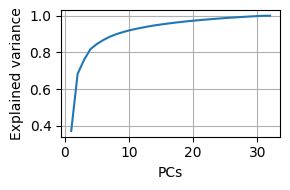

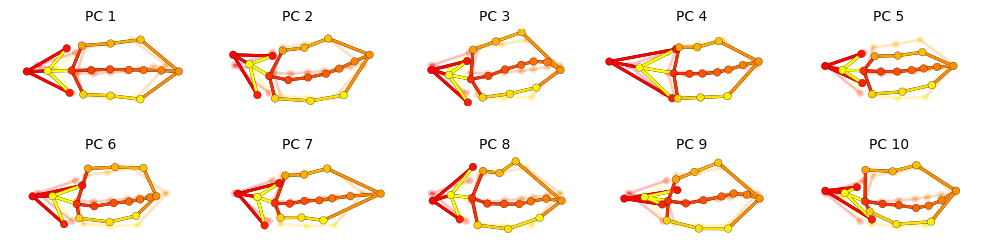

In [62]:
pca = kpms.fit_pca(**data, **config)
kpms.save_pca(pca, project_dir)

kpms.print_dims_to_explain_variance(pca, 0.9)
kpms.plot_scree(pca, project_dir=project_dir)
kpms.plot_pcs(pca, project_dir=project_dir, **config)
kpms.update_config(project_dir, latent_dim=8)

In [65]:
import logging
from tqdm import tqdm  # Ensure tqdm is imported if not already
from jax_moseq.utils import get_durations
import jax

def run_opt_kappa(model_idx, data, pca, metadata, project_dir):
    # OPT_KAPPA = 4.207e+05
    OPT_KAPPA = 1.205e+06
    kappa = OPT_KAPPA
    logging.info(f"Model {model_idx}: Starting AR-only fitting with kappa={kappa}")

    # --- AR-only fitting ---
    model = kpms.init_model(data, pca=pca, **config, seed=jax.random.PRNGKey(model_idx))
    num_ar_iters = 1
    model = kpms.update_hypparams(model, kappa=kappa)
    model, model_name = kpms.fit_model(
        model, data, metadata, project_dir,
        ar_only=True, num_iters=num_ar_iters)
    
    logging.info(f"Model {model_idx}: Completed AR-only fitting for model '{model_name}'. Loading checkpoint.")
    # Load the checkpoint after AR fitting.
    model, data, metadata, current_iter = kpms.load_checkpoint(
        project_dir, model_name, iteration=num_ar_iters)
    
    # --- Non-AR fitting ---
    fitting_iters = 1
    logging.info(f"Model {model_idx}: Starting non-AR fitting with adjusted kappa={kappa/10}.")
    model = kpms.update_hypparams(model, kappa=kappa/10)
    model_name = f'test_{kappa:.3e}_{model_idx}'
    model = kpms.fit_model(
        model, data, metadata, project_dir, model_name,
        ar_only=False, start_iter=current_iter, num_iters=current_iter + fitting_iters)[0]
    logging.info(f"Model {model_idx}: Completed non-AR fitting. Final model name: '{model_name}'.")
    kpms.reindex_syllables_in_checkpoint(project_dir, model_name)

    
    return model, model_name

Interpolating 189945 (0.6%) low-confidence keypoints
Keypoint SLDS: Initializing hyperparameters
Keypoint SLDS: Initializing noise prior
Keypoint SLDS: Initializing parameters
Keypoint SLDS: Initializing states
Outputs will be saved to ./demo_project/2025_06_17-16_56_18


 50%|██████████████████▌                  | 1/2 [00:11<00:11, 11.64s/it]

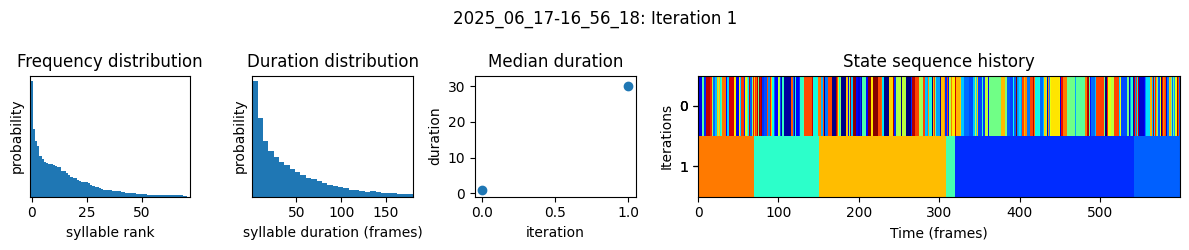

100%|█████████████████████████████████████| 2/2 [00:23<00:00, 11.50s/it]


Outputs will be saved to ./demo_project/test_1.205e+06_0


 50%|██████████████████                  | 1/2 [02:11<02:11, 131.45s/it]

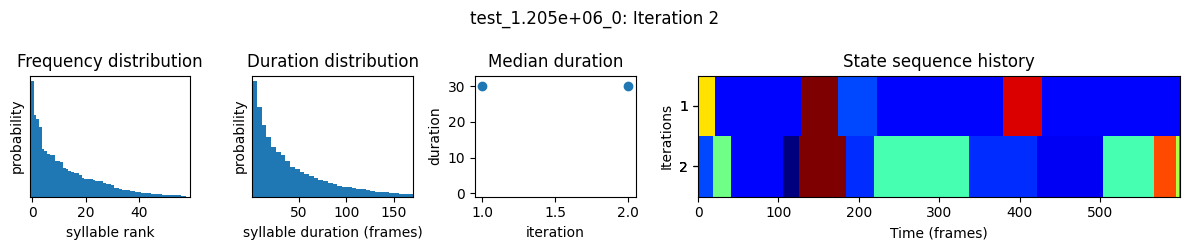

Reindexing: 100%|█████████████| 2/2 [00:00<00:00,  3.31model snapshot/s]


Interpolating 189945 (0.6%) low-confidence keypoints
Keypoint SLDS: Initializing hyperparameters
Keypoint SLDS: Initializing noise prior
Keypoint SLDS: Initializing parameters
Keypoint SLDS: Initializing states
Outputs will be saved to ./demo_project/2025_06_17-17_01_43


 50%|██████████████████▌                  | 1/2 [00:09<00:09,  9.82s/it]

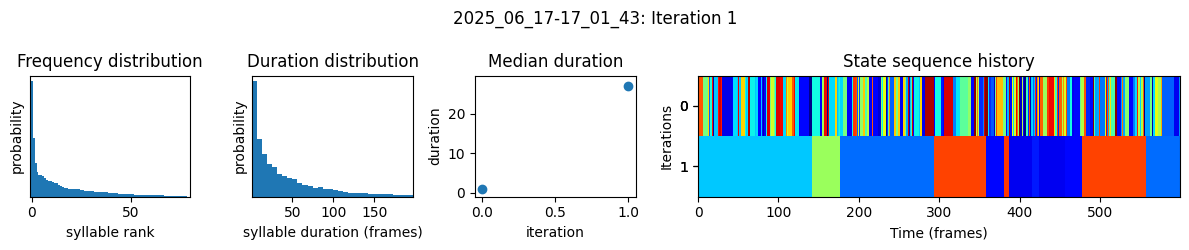

100%|█████████████████████████████████████| 2/2 [00:19<00:00,  9.90s/it]


Outputs will be saved to ./demo_project/test_1.205e+06_1


 50%|██████████████████                  | 1/2 [02:16<02:16, 136.58s/it]

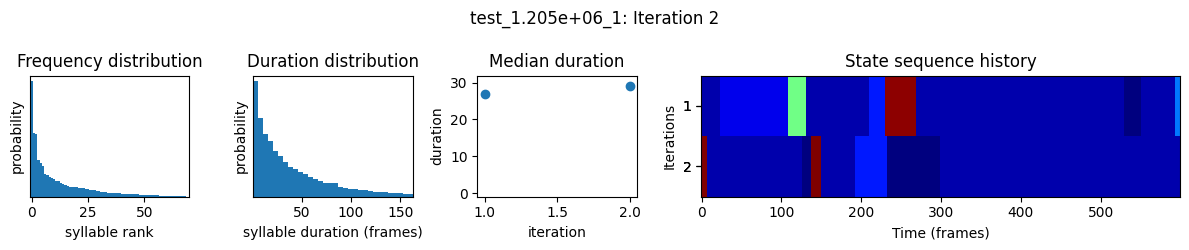

Reindexing: 100%|█████████████| 2/2 [00:00<00:00,  3.16model snapshot/s]


Interpolating 189945 (0.6%) low-confidence keypoints
Keypoint SLDS: Initializing hyperparameters
Keypoint SLDS: Initializing noise prior
Keypoint SLDS: Initializing parameters
Keypoint SLDS: Initializing states
Outputs will be saved to ./demo_project/2025_06_17-17_07_07


 50%|██████████████████▌                  | 1/2 [00:09<00:09,  9.77s/it]

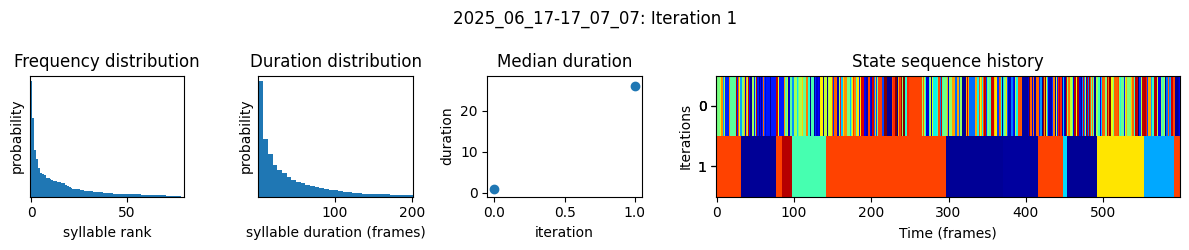

100%|█████████████████████████████████████| 2/2 [00:19<00:00,  9.89s/it]


Outputs will be saved to ./demo_project/test_1.205e+06_2


 50%|██████████████████                  | 1/2 [02:17<02:17, 137.46s/it]

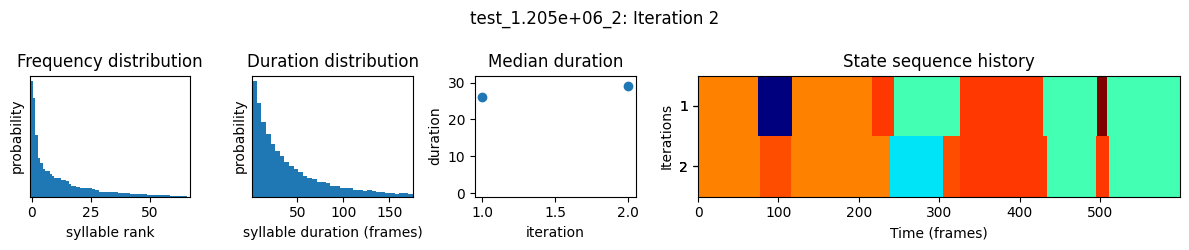

Reindexing: 100%|█████████████| 2/2 [00:00<00:00,  3.29model snapshot/s]


In [66]:
# commented kpms-processing loop
for model_idx in range(3):
    logging.info(f"Starting run for model index: {model_idx}")
    model, model_name = run_opt_kappa(model_idx, data, pca, metadata, project_dir)
    
    # # Process batches and apply model
    # for i, (coords_batch, confs_batch) in enumerate(tqdm(zip(batches_coords, batches_confs), total=len(batches_coords))):
    #     logging.info(f"Model '{model_name}': Processing batch {i}")
    #     data_batch, metadata_batch = kpms.format_data(coords_batch, confs_batch, **config())
    #     results = kpms.apply_model(model, data_batch, metadata_batch, project_dir, model_name, **config())
        
    #     # Append the batch index to the save directory to make it unique.
    #     save_directory = f"{project_dir}/{model_name}/results_batch_{i}"
    #     kpms.save_results_as_csv(results, project_dir, model_name, save_dir=save_directory)
    #     logging.info(f"Model '{model_name}': Saved results for batch {i} to '{save_directory}'")
    
    # logging.info(f"Completed all batches for model '{model_name}'")


In [ ]:
import os
import logging
from tqdm import tqdm
import numpy as np

# Discover model directories: these are folders starting with "kappa_opt_",
# that do not have "_first" in their name, and that contain a checkpoint file.
model_names = [
    d for d in os.listdir(project_dir)
    if os.path.isdir(os.path.join(project_dir, d))
    and d.startswith('kappa_opt_2d_multiple1.205e+06' + '_')
    and os.path.exists(os.path.join(project_dir, d, "checkpoint.h5"))
]

print(len(model_names))
logging.info("Computing expected marginal likelihood (EML) scores for models...")

# Option A: Use the vectorized function, wrapping the call in tqdm for a progress update.
eml_scores, eml_std_errs = kpms.expected_marginal_likelihoods(project_dir, model_names, num_samples=5)

# Identify the best model (highest EML score)
best_model = model_names[np.argmax(eml_scores)]
logging.info(f"Best model: {best_model} (params)")

# Plot the EML scores for all models
kpms.plot_eml_scores(eml_scores, eml_std_errs, model_names)


In [ ]:
model_prefix = 'kappa_opt_2d_multiple1.205e+06_'
curr_models = [model_prefix + n for n in ['12', '5', '2']]
curr_model = curr_models[-1]

In [ ]:
# for curr_model in curr_models:
model, data, metadata, current_iter = kpms.load_checkpoint(project_dir, curr_model)
results = kpms.extract_results(model, metadata, project_dir, curr_model)
# kpms.save_results_as_csv(results, project_dir, curr_model)
kpms.reindex_syllables_in_checkpoint(project_dir, curr_model)
kpms.generate_trajectory_plots(init_coords, results, project_dir, curr_model, density_sample=False, **config())
# kpms.plot_similarity_dendrogram(init_coords, results, project_dir, curr_model, **config())


In [ ]:
video_dir = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/SplitWithGPU_link'
video_paths = kpms.find_matching_videos(results.keys(), video_dir, as_dict=True)

In [ ]:
centroids, headings = kpms.get_centroids_headings(init_coords, **config())

In [ ]:
# results['Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020']
# output >>>
    # {'syllable': array([39, 39, 39, ...,  4,  4,  4]),
    #  'latent_state': array([[ 1.3631411 , -1.77911617,  4.06022262, ...,  0.32557411,
    #          -2.35876862,  0.63097214],
    #         [-4.30618763,  0.09293728,  2.43368568, ...,  2.83786993,
    #           0.1443892 ,  0.8489265 ],
    #         [-1.89452694, -0.458128  ,  2.74519373, ..., -1.36445389,
    #          -1.18977185,  1.09747477],
    #         ...,
    #         [ 0.35828769, -0.8425872 ,  0.65153164, ...,  0.80317387,
    #          -0.33257295, -0.2696416 ],
    #         [ 0.34998269, -0.94421821,  0.27307465, ...,  0.61384039,
    #           0.05480232, -0.36502581],
    #         [ 0.22378559, -1.30101386,  0.67329139, ...,  0.80032088,
    #          -0.55566528, -0.40049249]]),
    #  'centroid': array([[187.78317443, 188.79830498],
    #         [187.38175953, 190.12097765],
    #         [187.28401499, 189.43797403],
    #         ...,
    #         [ 88.83980381,  76.70061131],
    #         [ 90.23282051,  77.57987622],
    #         [ 90.81244248,  78.42125727]]),
    #  'heading': array([1.79069318, 2.01229705, 1.87446691, ..., 2.21262907, 2.298156  ,
    #         2.43542892])}

In [ ]:
kpms.generate_grid_movies(
    results,
    project_dir,
    curr_model,
    video_paths=video_paths,
    coordinates=init_coords,
    centroids=centroids,
    headings=headings,
    fps=60,
    video_frame_indexes=video_frame_indexes,
    **config()
)
# output >>>
# Writing grid movies to jonathan_ifdn/kappa_opt_2d_multiple1.205e+06_2/grid_movies
# Using window size of 128 pixels
# Generating grid movies: 100%|███████████| 48/48 [01:03<00:00,  1.32s/it]